In [4]:

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Load training datasets
train_set1 = pd.read_csv("train_set1.csv")
train_set2 = pd.read_csv("train_set2.csv")
train_set3 = pd.read_csv("train_set3.csv")

# Load test datasets
test_set1 = pd.read_csv("test_set1.csv")
test_set2 = pd.read_csv("test_set2.csv")
test_set3 = pd.read_csv("test_set3.csv")

# Separate features and target
X_train_set1 = train_set1.drop(columns=["Target"])
y_train_set1 = train_set1["Target"]

X_train_set2 = train_set2.drop(columns=["Target"])
y_train_set2 = train_set2["Target"]

X_train_set3 = train_set3.drop(columns=["Target"])
y_train_set3 = train_set3["Target"]

X_test_set1 = test_set1.drop(columns=["Target"])
y_test_set1 = test_set1["Target"]

X_test_set2 = test_set2.drop(columns=["Target"])
y_test_set2 = test_set2["Target"]

X_test_set3 = test_set3.drop(columns=["Target"])
y_test_set3 = test_set3["Target"]

print("Training and test datasets loaded successfully.")
print("Set 1:", X_train_set1.shape, X_test_set1.shape)
print("Set 2:", X_train_set2.shape, X_test_set2.shape)
print("Set 3:", X_train_set3.shape, X_test_set3.shape)


Training and test datasets loaded successfully.
Set 1: (3048, 7) (762, 7)
Set 2: (3048, 6) (762, 6)
Set 3: (3048, 6) (762, 6)


In [5]:

# Load the saved model bundles
dt_bundle = joblib.load("decision_tree_set2_ffs.joblib")
knn_bundle = joblib.load("knn_set1_ffs.joblib")
lr_bundle = joblib.load("logistic_regression_set1_ffs.joblib")
rf_bundle = joblib.load("random_forest_set3_ffs.joblib")
svm_bundle = joblib.load("svm_set1.joblib")

# Extract fitted estimators
models = {
    "Decision Tree (Set 2 FFS)": dt_bundle["model"],
    "KNN (Set 1 FFS)": knn_bundle["model"],
    "Logistic Regression (Set 1 FFS)": lr_bundle["model"],
    "Random Forest (Set 3 FFS)": rf_bundle["model"],
    "SVM (Set 1)": svm_bundle["model"]
}

# Match each model with its corresponding training and test data
datasets = {
    "Decision Tree (Set 2 FFS)": (
        X_train_set2, y_train_set2,
        X_test_set2, y_test_set2
    ),
    "KNN (Set 1 FFS)": (
        X_train_set1, y_train_set1,
        X_test_set1, y_test_set1
    ),
    "Logistic Regression (Set 1 FFS)": (
        X_train_set1, y_train_set1,
        X_test_set1, y_test_set1
    ),
    "Random Forest (Set 3 FFS)": (
        X_train_set3, y_train_set3,
        X_test_set3, y_test_set3
    ),
    "SVM (Set 1)": (
        X_train_set1, y_train_set1,
        X_test_set1, y_test_set1
    )
}

print("All five saved models loaded successfully.")


All five saved models loaded successfully.


In [6]:

results = []
predictions = {}
roc_data = {}

for name, model in models.items():

    X_train, y_train, X_test, y_test = datasets[name]

    # Read the required feature list from the saved bundle
    bundle = {
        "Decision Tree (Set 2 FFS)": dt_bundle,
        "KNN (Set 1 FFS)": knn_bundle,
        "Logistic Regression (Set 1 FFS)": lr_bundle,
        "Random Forest (Set 3 FFS)": rf_bundle,
        "SVM (Set 1)": svm_bundle
    }[name]

    required_features = bundle.get(
        "selected_features",
        bundle.get("feature_names", None)
    )

    # Fall back to all dataset columns if no feature list was saved
    if required_features is None:
        required_features = X_train.columns.tolist()

    missing_train = set(required_features) - set(X_train.columns)
    missing_test = set(required_features) - set(X_test.columns)

    if missing_train or missing_test:
        raise ValueError(
            f"{name}: missing training features {missing_train}; "
            f"missing test features {missing_test}"
        )

    # Preserve the feature order used by the model
    X_train_model = X_train[required_features]
    X_test_model = X_test[required_features]

    # Models are already fitted; do NOT fit on the test data
    y_train_pred = model.predict(X_train_model)
    y_test_pred = model.predict(X_test_model)

    # Calculate metrics
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    test_precision = precision_score(
        y_test, y_test_pred, average="macro", zero_division=0
    )
    test_recall = recall_score(
        y_test, y_test_pred, average="macro", zero_division=0
    )
    test_f1 = f1_score(
        y_test, y_test_pred, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Number of Features": len(required_features),
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Precision (Macro)": test_precision,
        "Recall (Macro)": test_recall,
        "F1-Score (Macro)": test_f1,
        "Train-Test Gap": train_accuracy - test_accuracy
    })

    predictions[name] = {
        "y_train": y_train,
        "y_train_pred": y_train_pred,
        "y_test": y_test,
        "y_test_pred": y_test_pred,
        "features": required_features
    }

    # ROC data for binary classification
    if len(model.classes_) == 2:
        positive_class = model.classes_[1]
        y_test_binary = (np.asarray(y_test) == positive_class).astype(int)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_test_model)[:, 1]
        elif hasattr(model, "decision_function"):
            scores = model.decision_function(X_test_model)
        else:
            scores = None

        if scores is not None:
            fpr, tpr, thresholds = roc_curve(y_test_binary, scores)
            auc = roc_auc_score(y_test_binary, scores)

            roc_data[name] = {
                "fpr": fpr,
                "tpr": tpr,
                "auc": auc,
                "positive_class": positive_class
            }

# Create the comparison table
results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Train Accuracy": "{:.2%}",
        "Test Accuracy": "{:.2%}",
        "Precision (Macro)": "{:.2%}",
        "Recall (Macro)": "{:.2%}",
        "F1-Score (Macro)": "{:.2%}",
        "Train-Test Gap": "{:.2%}"
    })
)


,Model,Number of Features,Train Accuracy,Test Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Train-Test Gap
0,Decision Tree (Set 2 FFS),3,94.00%,91.34%,91.39%,90.88%,91.10%,2.66%
1,KNN (Set 1 FFS),2,93.57%,91.21%,91.37%,90.65%,90.95%,2.36%
2,Logistic Regression (Set 1 FFS),5,93.57%,92.13%,92.35%,91.57%,91.89%,1.44%
3,Random Forest (Set 3 FFS),3,93.73%,91.47%,91.43%,91.11%,91.26%,2.26%
4,SVM (Set 1),7,93.57%,91.86%,91.93%,91.42%,91.64%,1.71%


In [7]:

# Add training precision, recall, and F1-score
for row in results:
    name = row["Model"]
    data = predictions[name]

    row["Train Precision (Macro)"] = precision_score(
        data["y_train"],
        data["y_train_pred"],
        average="macro",
        zero_division=0
    )

    row["Train Recall (Macro)"] = recall_score(
        data["y_train"],
        data["y_train_pred"],
        average="macro",
        zero_division=0
    )

    row["Train F1-Score (Macro)"] = f1_score(
        data["y_train"],
        data["y_train_pred"],
        average="macro",
        zero_division=0
    )

results_df = pd.DataFrame(results)

metric_columns = [
    "Train Accuracy",
    "Train Precision (Macro)",
    "Train Recall (Macro)",
    "Train F1-Score (Macro)",
    "Test Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-Score (Macro)"
]

display(
    results_df[
        ["Model", "Number of Features"] + metric_columns
    ].style.format({
        column: "{:.2%}" for column in metric_columns
    })
)


,Model,Number of Features,Train Accuracy,Train Precision (Macro),Train Recall (Macro),Train F1-Score (Macro),Test Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Decision Tree (Set 2 FFS),3,94.00%,93.85%,93.89%,93.87%,91.34%,91.39%,90.88%,91.10%
1,KNN (Set 1 FFS),2,93.57%,93.46%,93.39%,93.43%,91.21%,91.37%,90.65%,90.95%
2,Logistic Regression (Set 1 FFS),5,93.57%,93.46%,93.39%,93.43%,92.13%,92.35%,91.57%,91.89%
3,Random Forest (Set 3 FFS),3,93.73%,93.62%,93.58%,93.60%,91.47%,91.43%,91.11%,91.26%
4,SVM (Set 1),7,93.57%,93.43%,93.43%,93.43%,91.86%,91.93%,91.42%,91.64%


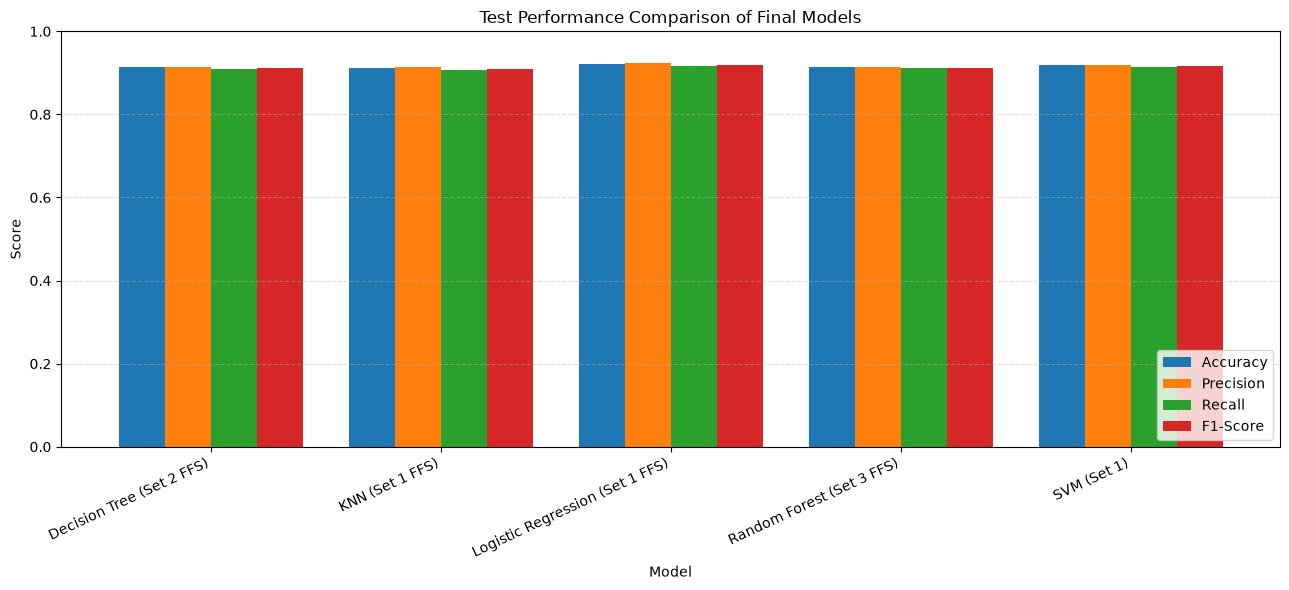

In [8]:

test_metric_columns = [
    "Test Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-Score (Macro)"
]

plot_df = results_df.set_index("Model")[test_metric_columns]

ax = plot_df.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Test Performance Comparison of Final Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
ax.legend(
    ["Accuracy", "Precision", "Recall", "F1-Score"],
    loc="lower right"
)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


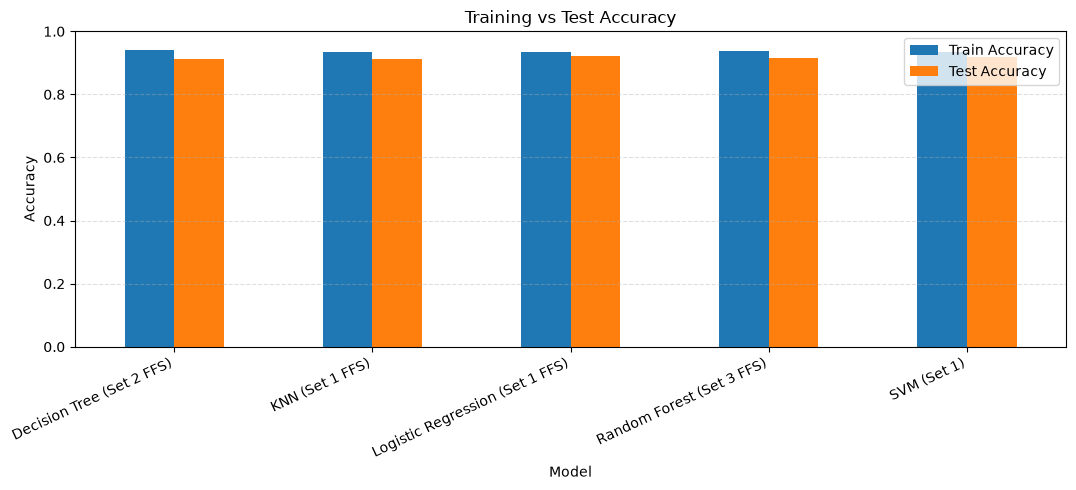

In [9]:

accuracy_plot = results_df.set_index("Model")[
    ["Train Accuracy", "Test Accuracy"]
]

ax = accuracy_plot.plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1)
)

ax.set_title("Training vs Test Accuracy")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Model")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


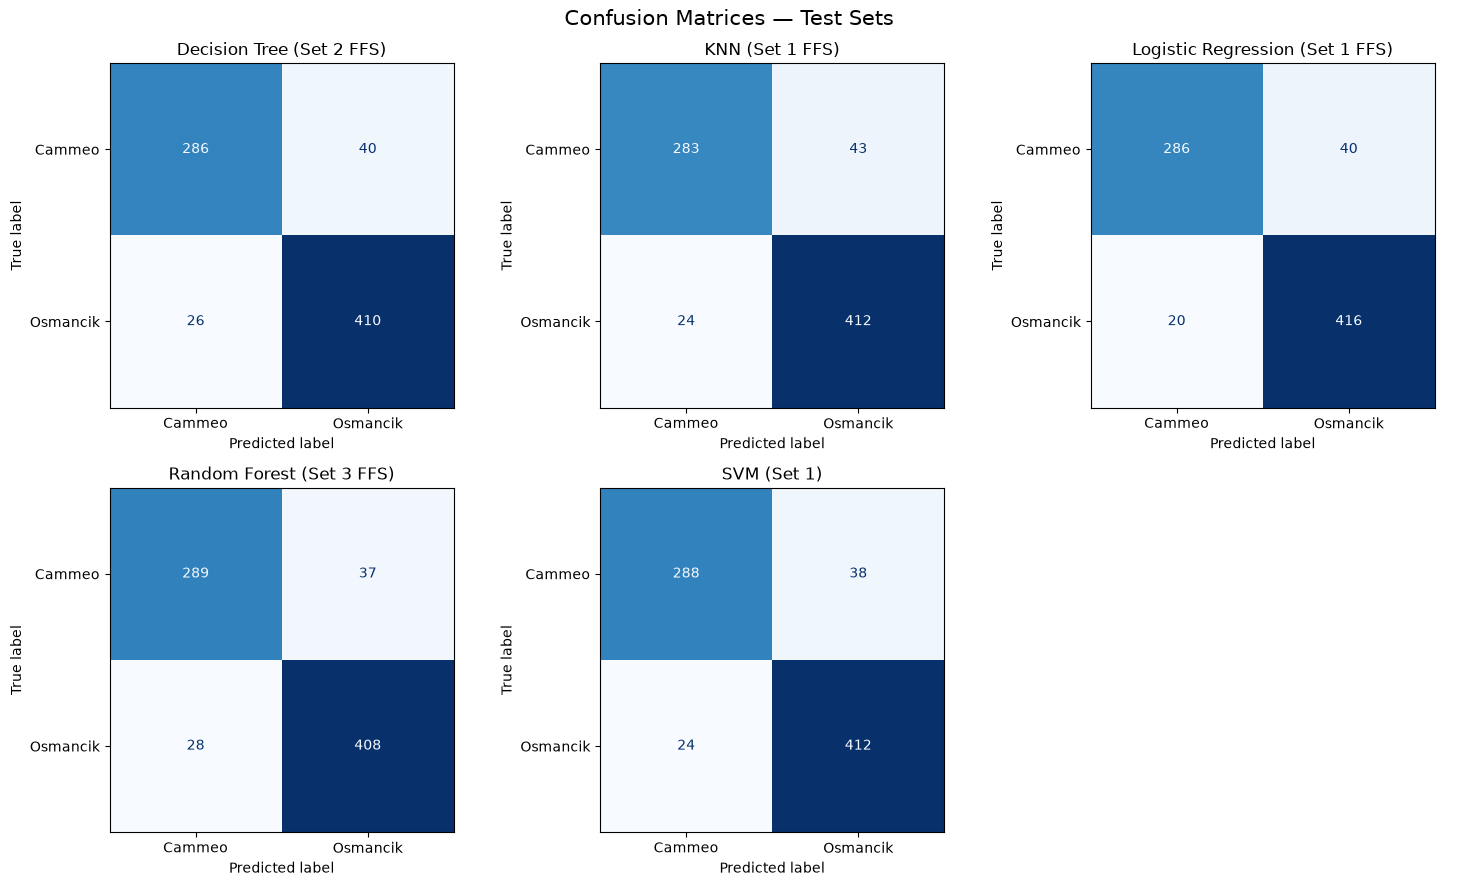

In [10]:

from sklearn.utils.multiclass import unique_labels

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for i, (name, data) in enumerate(predictions.items()):
    cm = confusion_matrix(
        data["y_test"],
        data["y_test_pred"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=unique_labels(data["y_test"])
    )

    disp.plot(
        ax=axes[i],
        cmap="Blues",
        colorbar=False
    )
    axes[i].set_title(name)

# Hide the unused sixth subplot
for j in range(len(predictions), len(axes)):
    axes[j].axis("off")

plt.suptitle("Confusion Matrices — Test Sets", fontsize=15)
plt.tight_layout()
plt.show()


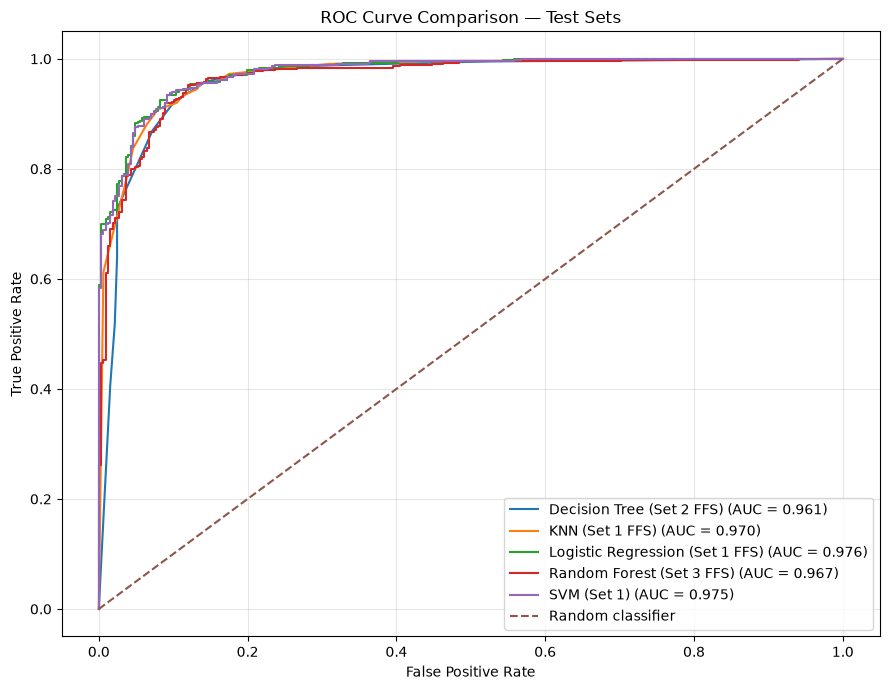

,Model,Positive Class,ROC AUC
0,Decision Tree (Set 2 FFS),Osmancik,0.9615
1,KNN (Set 1 FFS),Osmancik,0.9701
2,Logistic Regression (Set 1 FFS),Osmancik,0.9759
3,Random Forest (Set 3 FFS),Osmancik,0.9666
4,SVM (Set 1),Osmancik,0.9753


In [11]:

plt.figure(figsize=(9, 7))

for name, data in roc_data.items():
    plt.plot(
        data["fpr"],
        data["tpr"],
        label=f"{name} (AUC = {data['auc']:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — Test Sets")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display the AUC scores
auc_df = pd.DataFrame([
    {
        "Model": name,
        "Positive Class": data["positive_class"],
        "ROC AUC": data["auc"]
    }
    for name, data in roc_data.items()
])

display(auc_df.style.format({"ROC AUC": "{:.4f}"}))


In [12]:

for name, data in predictions.items():
    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            data["y_test"],
            data["y_test_pred"],
            zero_division=0
        )
    )


Decision Tree (Set 2 FFS)
              precision    recall  f1-score   support

      Cammeo       0.92      0.88      0.90       326
    Osmancik       0.91      0.94      0.93       436

    accuracy                           0.91       762
   macro avg       0.91      0.91      0.91       762
weighted avg       0.91      0.91      0.91       762

KNN (Set 1 FFS)
              precision    recall  f1-score   support

      Cammeo       0.92      0.87      0.89       326
    Osmancik       0.91      0.94      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.91      0.91       762
weighted avg       0.91      0.91      0.91       762

Logistic Regression (Set 1 FFS)
              precision    recall  f1-score   support

      Cammeo       0.93      0.88      0.91       326
    Osmancik       0.91      0.95      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.92      0.92       762


In [13]:

results_df.to_csv(
    "final_model_test_comparison.csv",
    index=False
)

if not auc_df.empty:
    auc_df.to_csv("final_model_roc_auc.csv", index=False)

print("Saved final_model_test_comparison.csv")
print("Saved final_model_roc_auc.csv")


Saved final_model_test_comparison.csv
Saved final_model_roc_auc.csv


## Final Model Selection and Conclusion

After evaluating the five saved machine learning models on their corresponding test datasets, **Logistic Regression with Set 1 and Forward Feature Selection (FFS)** is selected as the preferred final model for the rice classification task.

The Logistic Regression model achieved the highest test accuracy of **92.13%**, macro precision of **92.35%**, macro recall of **91.57%**, and macro F1-score of **91.89%**. It uses five input features and has a training–test accuracy gap of 1.44 percentage points, indicating a relatively small difference between its performance on training and unseen test data.

Although the Decision Tree achieved a higher training accuracy of 94.00%, its test accuracy was 91.34%. Similarly, the Random Forest achieved 91.47% test accuracy, while KNN achieved 91.21%. The SVM model achieved 91.86% test accuracy and the highest training–test gap comparison is not the main selection criterion; its test precision was 91.93%, which is lower than that of Logistic Regression.

KNN is the most feature-efficient model, using only two features, while Decision Tree and Random Forest use three features each. However, their lower test performance suggests that the additional simplicity does not compensate for the predictive performance achieved by Logistic Regression in this evaluation.

Overall, **Logistic Regression (Set 1 FFS) provides the best balance of test accuracy, precision, recall, and F1-score** among the evaluated models. Therefore, it is selected as the final candidate for rice variety classification. This conclusion assumes that all models were evaluated on equivalent test observations with consistent target labels. The selected model should be retained with its preprocessing pipeline and selected feature list so that future predictions use the same input features and transformations as training.
